In [1]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import random
import numpy as np

In [3]:
df = pd.read_parquet(r'..\data\processed\options_features.parquet')

abs params: [-0.195  0.819  0.757  0.697  0.389]
rel params: [ 0.009  0.086 -0.485  0.133  0.05 ]


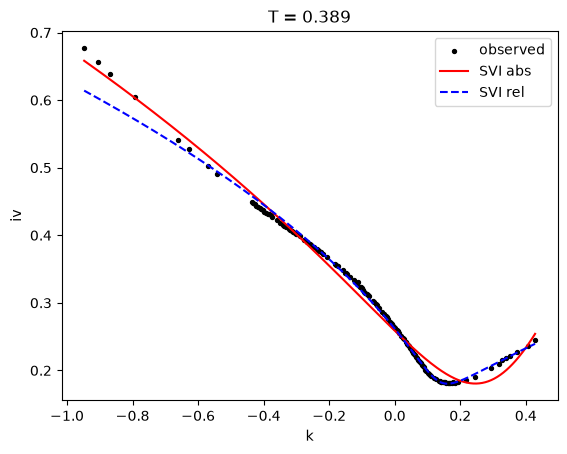

In [12]:
from src.models.svi import SVIModel, SVIRelModel, fit_slice, svi_w
import matplotlib.pyplot as plt

T0 = diag.iloc[0]['T']                                    # worst slice from diagnostics
s = vis[np.isclose(vis['T'], T0)].sort_values('k')
w_obs = (s['iv']**2 * T0).to_numpy()

p_abs, _ = fit_slice(s['k'], w_obs, rel=False)
p_rel, _ = fit_slice(s['k'], w_obs, rel=True)
print('abs params:', np.round(p_abs, 3))
print('rel params:', np.round(p_rel, 3))

kk = np.linspace(s['k'].min(), s['k'].max(), 300)
plt.scatter(s['k'], s['iv'], s=8, c='k', label='observed')
plt.plot(kk, np.sqrt(svi_w(kk, *p_abs) / T0), 'r', label='SVI abs')
plt.plot(kk, np.sqrt(svi_w(kk, *p_rel) / T0), 'b--', label='SVI rel')
plt.title(f'T = {T0:.3f}'); plt.xlabel('k'); plt.ylabel('iv'); plt.legend(); plt.show()

In [13]:
for name, fn in masks.items():
    all_res.append(evaluate(SVIRelModel, df, test_days, fn, name))
res4 = pd.concat(all_res, ignore_index=True)
print(res4.pivot_table(index='model', columns='mask', values='rmse', aggfunc='mean').round(2))
res4.to_csv('../results/b1_july2020.csv', index=False)

mask       expiry  random   wing
model                           
linear       0.38    0.28   5.78
linear_iv    0.44    0.38   7.17
mean        11.00   11.82  20.48
svi          0.90    0.78   3.67
svi_rel      0.90    0.82   3.78
